# დიაბეტის პრედიქცია — სრული ML Pipeline

ეს ნოუთბუქი მოიცავს დიაბეტის მონაცემთა ნაკრების სრულ ანალიზს:

1. მონაცემების გაცნობა და EDA
2. წინასწარი დამუშავება
3. მოდელების სწავლება **ჯვარედინი ვალიდაციით**
4. შედეგების შედარება და ინტერპრეტაცია

## კოდების გაშვებისთვის საჭირო ბიბლიოთეკების იმპორტები

ამ ნოუთბუქის გაშვებამდე არ დაგავიწყდეთ საჭირო დამოკიდებულებების დაინსტალირება:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn
```

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

## კონფიგურაციები

In [2]:
pd.options.display.max_columns = None
sns.set_style("whitegrid")
RANDOM_STATE = 21

## 1. მონაცემების ჩატვირთვა

In [3]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [4]:
df.shape

(768, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


მოგესალმებით ქალბატონო მარიამ , დილის 6 ის ნახევარია და იმედია სისულელებს არ ვიბუდინებ , შეცეცდები უფრო დეტალურად და კონკრეტული ვიყო დღეს , პირველ რიგში ვიწყებთ მოცაემებზე დაკვირვებით , როგორც ცხრილიდან ვნახე რაღაც მონაცემები გამოტოვებულია , სწორედ ამიტომ შევაცადე ქლაუდს შეენიშნა ესენი და ეს გამოტოვებული მონაცემები რამით შეევსო , ჯამშ გვაქ 768 აგრეგატი , რომელიც შედღება ინტებისა და ფლოატებისგან , მაგრამ მაგალითად skinthikness , insulin , BMI ,glucose და bloodpressure გვაქ მონაცემთა დანაკლისი , რანდომ სტეიტი 21 მივუთითე რატომღაც , თქვენს ლექციის მასალაში ვნახე და არ ვიცი სიმართლე გითხრათ რას შეცვლის მაგრამ დავაკვირდები.

## 2. EDA — მონაცემების შესწავლა

### 2.1 სამიზნე ცვლადის განაწილება

პირველ რიგში ვნახოთ, გვაქვს თუ არა კლასების დისბალანსი:

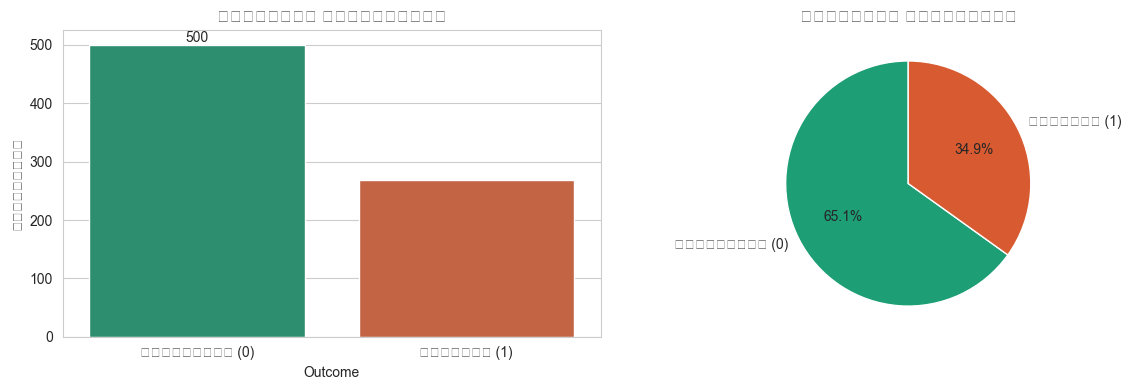

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

outcome_counts = df["Outcome"].value_counts()
ax = sns.barplot(
    x=outcome_counts.index,
    y=outcome_counts.values,
    palette=["#1D9E75", "#D85A30"],
    ax=axes[0],
)
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["ჯანმრთელი (0)", "დიაბეტი (1)"])
axes[0].set_title("კლასების განაწილება")
axes[0].set_ylabel("რაოდენობა")

axes[1].pie(
    outcome_counts.values,
    labels=["ჯანმრთელი (0)", "დიაბეტი (1)"],
    autopct="%1.1f%%",
    colors=["#1D9E75", "#D85A30"],
    startangle=90,
)
axes[1].set_title("კლასების პროპორცია")

plt.tight_layout()
plt.show()

შემდეგ კი ვაწყდებით დიაბედტა დავააადებულთა და ჯანმრთელთა ადამიანების განაწილებას , გვყავს 500 ადამინაი რომელიც არ არის დაავადებული ,ხოლო 268 დაავადებულია, მათ განაწილებას ხედავთ
ზემოდ ხსენებულ წრიულ და კუბების დიაგრამაში :დ

### 2.2 გამოტოვებული მნიშვნელობები

ამ მონაცემთა ნაკრებში გამოტოვებული მნიშვნელობები `NaN`-ის სახით მოდის (CSV-ში ასე შენახულია):

In [7]:
pd.DataFrame(
    {
        "გამოტოვებულთა რაოდენობა": df.isna().sum(),
        "გამოტოვებულთა პროცენტი": (df.isna().sum() / len(df) * 100)
        .round(2)
        .astype(str)
        + "%",
    },
    index=df.columns,
)

,გამოტოვებულთა რაოდენობა,გამოტოვებულთა პროცენტი
Pregnancies,0,0.0%
Glucose,5,0.65%
BloodPressure,35,4.56%
SkinThickness,227,29.56%
Insulin,374,48.7%
BMI,11,1.43%
DiabetesPedigreeFunction,0,0.0%
Age,0,0.0%
Outcome,0,0.0%


აქ კი მე და ქლაუდმა გამოვიტანეთ გამოტოვებულთა მონაცემების რაოდენობა კონკრეტულ საკითხებში.

### 2.3 ძირითადი სტატისტიკა

In [8]:
df.describe().style.format("{:.2f}")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,763.00,733.00,541.00,394.00,757.00,768.00,768.00,768.00
mean,3.85,121.69,72.41,29.15,155.55,32.46,0.47,33.24,0.35
std,3.37,30.54,12.38,10.48,118.78,6.92,0.33,11.76,0.48
min,0.00,44.00,24.00,7.00,14.00,18.20,0.08,21.00,0.00
25%,1.00,99.00,64.00,22.00,76.25,27.50,0.24,24.00,0.00
50%,3.00,117.00,72.00,29.00,125.00,32.30,0.37,29.00,0.00
75%,6.00,141.00,80.00,36.00,190.00,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


შემდეგ კი მნიშვნელოვანი ნაწილი რომ ჩამიმიყალიბდეს მონაცემებზე კონკრეტული აზრი , საშუალო და 50 პროცენტილი იძლევა სხვაობას , რაც ეჭვს მიბადებს რომ არის ძალიან მცირე underfeat , თუ არასწორია გდხოვთ შემისწოროთ , ასევე კონკრეტულ საკითხებში კუდი შედარებბით უფრო მარცხნივ აქვს წავარდნილი , ვნახავთ გრაფებზე , არის რაღაც მონაცემები რაშიც მცირეოდენი სხვაობაა მაგრამ ძირითადად კუდგაგდებულია :დ

### 2.4 ნიშნების განაწილება Outcome-ის მიხედვით

ვნახოთ, თუ რომელი ნიშანი ყველაზე მეტ განსხვავებას გვიჩვენებს დიაბეტური და ჯანმრთელი პაციენტების შორის:

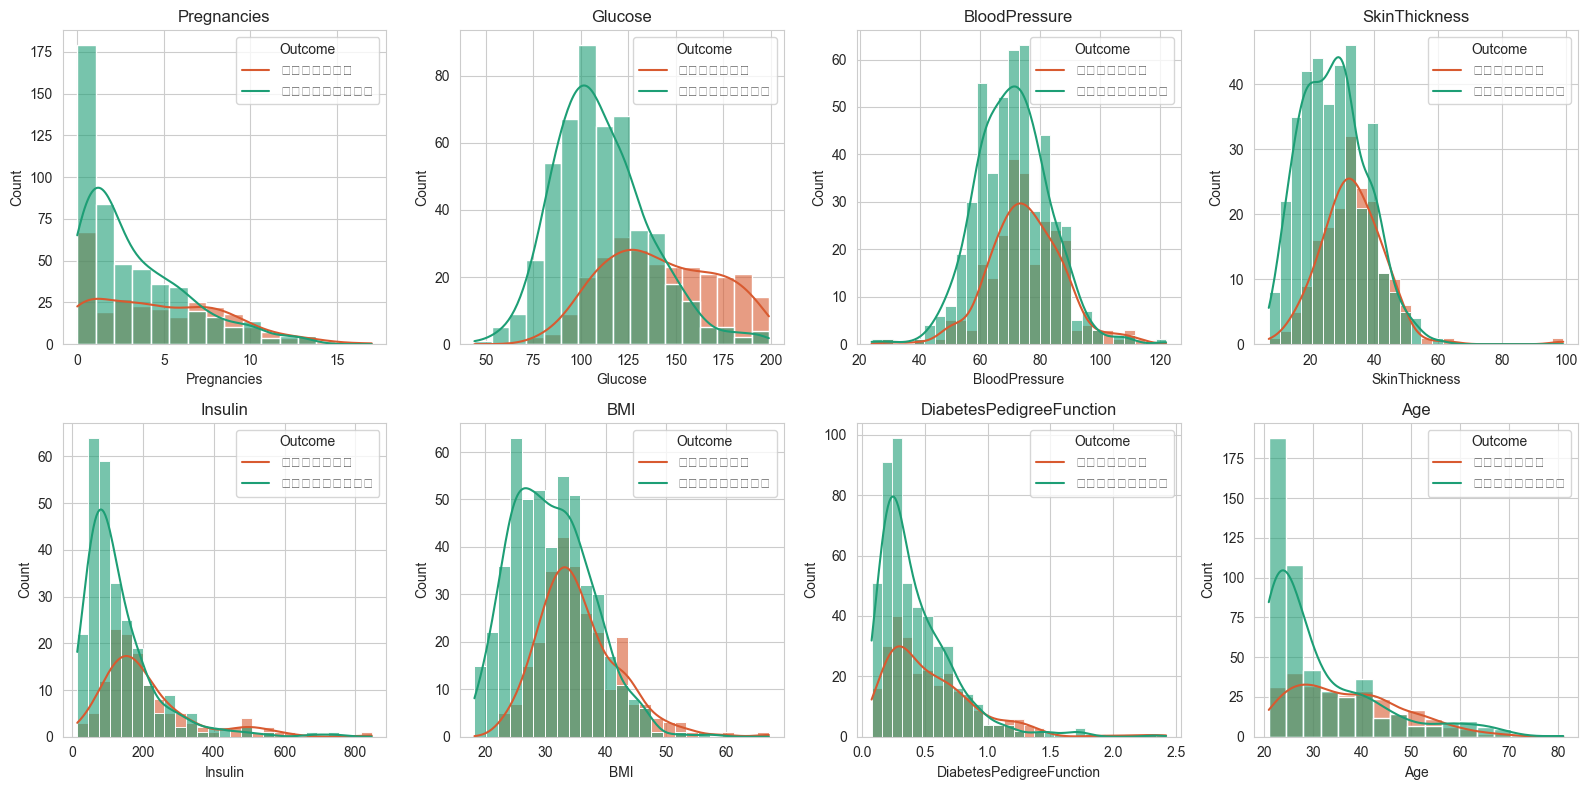

In [9]:
feature_cols = [c for c in df.columns if c != "Outcome"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

palette = {0: "#1D9E75", 1: "#D85A30"}

for i, col in enumerate(feature_cols):
    sns.histplot(
        data=df,
        x=col,
        hue="Outcome",
        kde=True,
        palette=palette,
        ax=axes[i],
        alpha=0.6,
    )
    axes[i].set_title(col)
    axes[i].legend(title="Outcome", labels=["დიაბეტი", "ჯანმრთელი"])

plt.tight_layout()
plt.show()

აქ კი ჩემი ზემოდხსენებული ჰიპოთეზა დასტურდება :დ , სავარაუდოდ ნორმალიზაციაზე მეტად კონკრეტული გრაფები სტანდარტიზაციისკენ მიისწრაფის ,ან თუ არ მიისწრაფის აშკარად საჭიროებს , არასტაბილურის შთაბეჭდილებას მიტოვებს ერთი შეხედვით 

### 2.5 კორელაციის მატრიცა

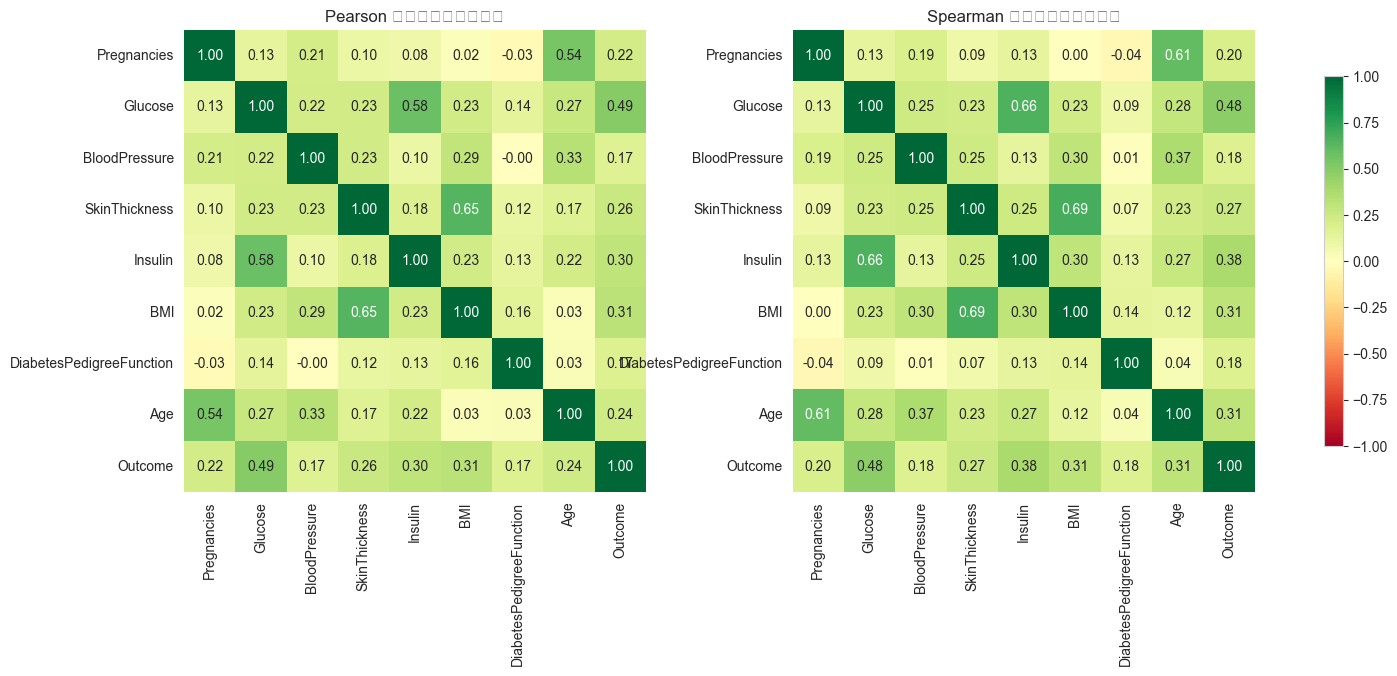

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(
        df.corr(method=method),
        annot=True,
        fmt=".2f",
        square=True,
        vmin=-1,
        vmax=1,
        cmap="RdYlGn",
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"{method.capitalize()} კორელაცია")

fig.colorbar(axes[0].collections[0], ax=axes, shrink=0.8)
plt.show()

მჰჰჰჰ , ასევე რაღაც პატარა დაკვირვება გავაკეთე pearson და spearman ის შესახებ მოვიძიე რაღაც როგორც ჩანს ორივე მონაცემებს შორის კავშირის ძიებაზეა პასუხისმგებელი ოღონდ სხვადასხვა გზით , და ამ კორელაციის მატრიცამაც დამაფიქრა შევეცდები ავხსნა რა მხრივ , მაგალითად ორსულობა შედარებით უფრო შესამჩნევია შედარებით ასოკოვან ადამიანებში რაც ცვლადებზე ახდენს გავლენას(კიდევ კაი მასეა) , ასევე ბუნებრივი შაქარი (გლუკოზა) უფრო მაღალია ისეთ ადამიანებში რომელიც ინსულინს მოიხმარენ , კანთან დაკავშირებული პრობლემები კი BMIსთან არის დაკავშირებული , ძალიან საინტერესოა ეგ ფაქტი რომ მანქანას ამათ შორის რაღაც ლოგიკური კავშირის დანახვა შეუძლია

### 2.6 Boxplot — Outcome-ის მიხედვით

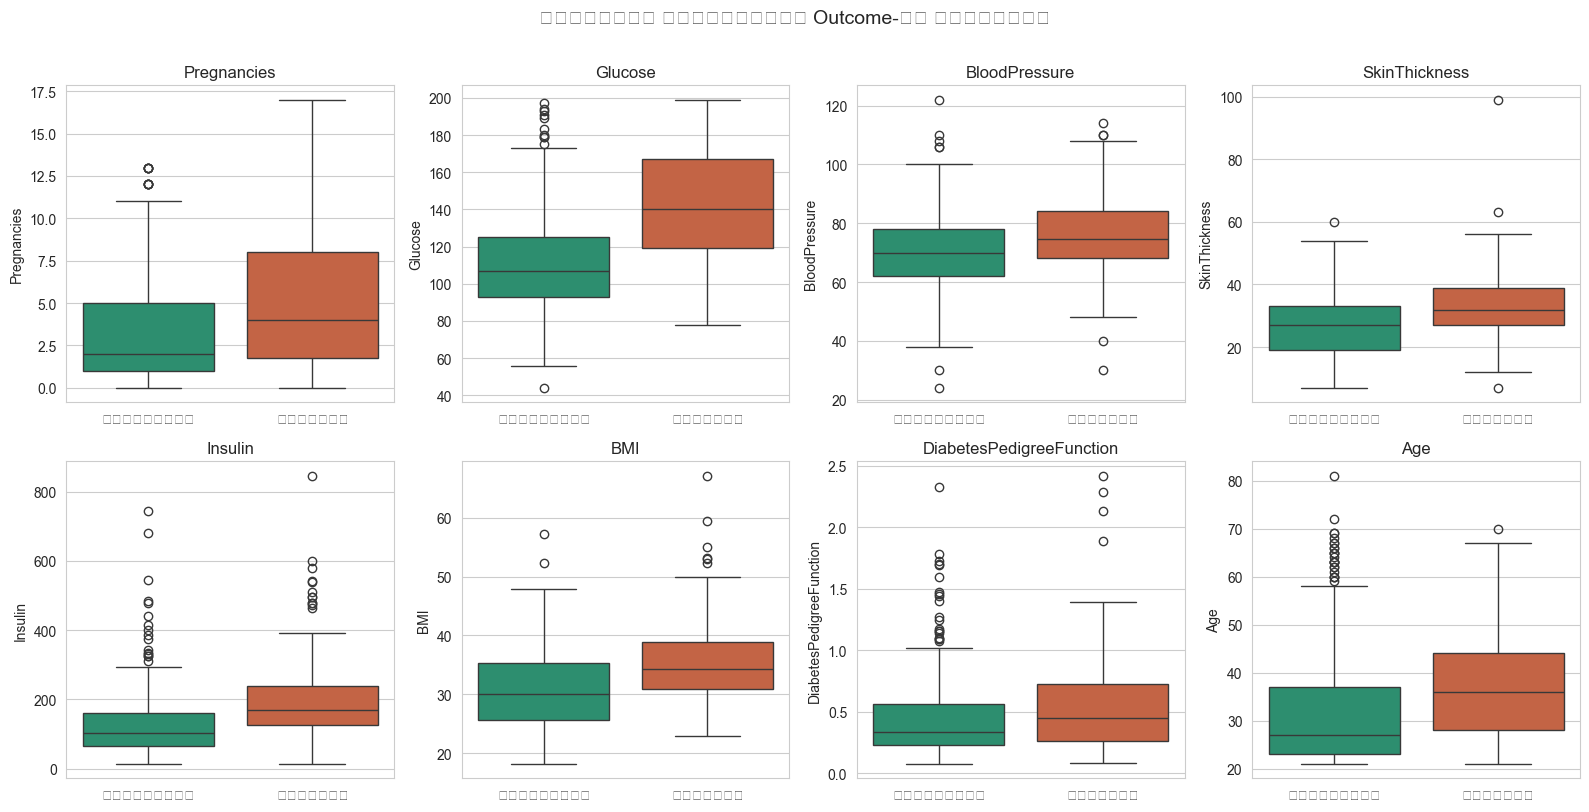

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(
        data=df,
        x="Outcome",
        y=col,
        hue="Outcome",
        palette=palette,
        ax=axes[i],
        legend=False,
    )
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["ჯანმრთელი", "დიაბეტი"])

plt.suptitle("ნიშნების განაწილება Outcome-ის მიხედვით", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

შემდეგი კი box plot , აქ კი აშკარად ვხედავთ outlierebს , მაგრამ ყველაზე თვალში საცემი რაც არის და ასევე ლუგიკური გლუკოზის ბოქსია :დ , ისევ მაიცებს კომპიუტერები , ყვეკაზე მეტი outlierი შეიმჩნევა ასაკში არადიაბეტით დაავადებულ ადამიანებში , ინსულინით და ასევე კლუკოზის ცხრილში საინტერესოა ძალზედ კიდევ რას მეუბნება ეს ცხრილები შემდეგ ლექციაზე ორივე ყურს დაგიგდებთ 

## 3. მონაცემების წინასწარი დამუშავება

### 3.1 ნიშნებისა და სამიზნე ცვლადის გამოყოფა

In [12]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"y განაწილება:\n{y.value_counts()}")

X shape: (768, 8)
y shape: (768,)
y განაწილება:
Outcome
0    500
1    268
Name: count, dtype: int64


### 3.2 გამოტოვებული მნიშვნელობების შევსება (Median Imputation)

ვიყენებთ მედიანას საშუალოს ნაცვლად, რადგან ზოგიერთ სვეტში (Insulin, SkinThickness) მკვეთრი დახრილობა (skewness) გვაქვს — მედიანა მდგრადია outlier-ების მიმართ:

In [13]:
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

print("გამოტოვებული მნიშვნელობები imputation-ის შემდეგ:")
print(X_imputed.isna().sum())

გამოტოვებული მნიშვნელობები imputation-ის შემდეგ:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


### 3.3 სტანდარტიზაცია (StandardScaler)

K-Means-ის მსგავსად, ლოგისტიკური რეგრესია და SVM მგრძნობიარეა მახასიათებლების მასშტაბის მიმართ — ვასტანდარტიზებთ ყველა ნიშანს:

In [14]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_imputed), columns=X.columns)

X_scaled.describe().style.format("{:.2f}")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,-0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.14,-2.55,-4.00,-2.52,-1.47,-2.07,-1.19,-1.04
25%,-0.84,-0.72,-0.69,-0.47,-0.22,-0.72,-0.69,-0.79
50%,-0.25,-0.15,-0.03,-0.01,-0.18,-0.02,-0.30,-0.36
75%,0.64,0.61,0.63,0.33,-0.16,0.60,0.47,0.66
max,3.91,2.54,4.10,7.96,8.17,5.04,5.88,4.06


### 3.4 Train/Test გაყოფა

`stratify=y` გამოვიყენეთ, რომ train და test set-ებში კლასების პროპორცია შენარჩუნდეს:

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train size: {X_train.shape[0]} ({X_train.shape[0]/len(X_scaled)*100:.1f}%)")
print(f"Test size:  {X_test.shape[0]} ({X_test.shape[0]/len(X_scaled)*100:.1f}%)")
print(f"\nTrain კლასების პროპორცია:")
print(y_train.value_counts(normalize=True).round(3))
print(f"\nTest კლასების პროპორცია:")
print(y_test.value_counts(normalize=True).round(3))

Train size: 614 (79.9%)
Test size:  154 (20.1%)

Train კლასების პროპორცია:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Test კლასების პროპორცია:
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


აქიდან კი გადავდივართ მონაცემების მოსამზადებლად , პირველ რიგში გამოვყოფთ სამიზნე ცვლადებს , შემდეგ კი გამოტოვებულ მნიშვნელობებს ვანაცვლებთ , რადგან ლოგისტკური რეგრესია და სვმ ფაქიზები არიან , როგორც cloude მა გადაწყვიტა მონაცემები უნდა დაასტანდარტიზოს , სიმართლე გითხრათ უარყოფითი ნიშნები რომ ვნახე შემეშინდა ცოტათი , მაგრამ ეხლა ვხდები რისთვისაც სჭირდება , ალბათ ბზა მონაცმები , კონკრეტულ ალგორითმებს გადაიყვანს უაზრო ოვერფიტში , სწორედ მაგიტომ სჭირდებათ მონაცემების დასტაბულურება , რომ უფრო ლეგიტიმურად იმუშაონ , იმედია არ ვცდები , შემდეგ კი გავყავით  სატესტო და ტრენინინგად 80 20 ზე 21 რანდომ სტეითით

## 4. ჯვარედინი ვალიდაცია (Stratified K-Fold Cross-Validation)

ჯვარედინი ვალიდაცია (Cross-Validation) არის მოდელის შეფასების ტექნიკა, რომელიც train set-ს K ნაწილად ყოფს, თითოეულ ჯერზე K-1 ნაწილს სწავლებაზე იყენებს და დარჩენილს ვალიდაციაზე. ეს:

* **ამცირებს overfitting-ის რისკს** — შედეგი ერთ split-ზე არ არის დამოკიდებული
* **გვაძლევს სტატისტიკურ სტაბილობას** — ვხედავთ მოდელის სტანდარტულ გადახრასაც
* **ეფექტიანად იყენებს მონაცემებს** — ყველა წერტილი ვალიდაციაზე ერთხელ მაინც გამოიყენება

`StratifiedKFold` გამოვიყენეთ, რომ ყოველ fold-ში კლასების პროპორცია შენარჩუნდეს:

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(random_state=RANDOM_STATE, max_iter=[1000] , C=[0.001, 0.01, 0.1, 1, 10, 100], penalty=["l1", "l2" , 'elasticnet'], solver=['lbfgs','liblinear','saga'], class_weight=['balanced', None]),
    "Random Forest": RandomForestClassifier(n_estimators=[100, 200, 300], random_state=RANDOM_STATE , max_depth=[None, 5, 10 ,15], min_samples_split=[2, 5, 10], min_samples_leaf=[1, 2, 4], class_weight=['balanced', None] , max_features=['sqrt', 'log2', None]),
    "Gradient Boosting": GradientBoostingClassifier(max_depth=[3,4,5,6], learning_rate=[0.01,0.05,0.1,0.2],subsample=[0.7,0.8,0.9,1.0],
        n_estimators=[100, 200, 300], random_state=RANDOM_STATE
    ),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE, C=[0.1, 1, 10, 100], kernel=['linear', 'rbf'], class_weight=['balanced', None]),
}

In [17]:
cv_results = {}

scoring = ["accuracy", "roc_auc", "f1", "precision", "recall"]

for name, model in models.items():
    cv_results = {}
    scoring = ["accuracy", "roc_auc", "f1", "precision", "recall"]

    for name, model in models.items():
        cv_results = {}
        scoring = ["accuracy", "roc_auc", "f1", "precision", "recall"]

        models = {
            "Logistic Regression": LogisticRegression(
                random_state=RANDOM_STATE,
                max_iter=1000,
                penalty="l2",
                solver="liblinear",
                class_weight="balanced",
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                class_weight="balanced",
                max_features="sqrt",
            ),
            "Gradient Boosting": GradientBoostingClassifier(
                max_depth=3,
                learning_rate=0.1,
                subsample=1.0,
                n_estimators=100,
                random_state=RANDOM_STATE,
            ),
            "SVM": SVC(
                probability=True,
                random_state=RANDOM_STATE,
                C=1.0,
                kernel="rbf",
                class_weight="balanced",
            ),
        }

        for name, model in models.items():
            results = cross_validate(
                model,
                X_train,
                y_train,
                cv=cv,
                scoring=scoring,
                return_train_score=True,
                n_jobs=-1,
            )
            cv_results[name] = results
            print(f"✓ {name} — დასრულდა")
        cv_results[name] = results
        print(f"✓ {name} — დასრულდა")
    cv_results[name] = results
    print(f"✓ {name} — დასრულდა")

✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა
✓ SVM — დასრულდა
✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა
✓ SVM — დასრულდა
✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა
✓ SVM — დასრულდა
✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა
✓ SVM — დასრულდა
✓ SVM — დასრულდა
✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა
✓ SVM — დასრულდა
✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა
✓ SVM — დასრულდა
✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა
✓ SVM — დასრულდა
✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა


### 4.1 CV შედეგების შეჯამება

In [18]:
summary_rows = []

for name, res in cv_results.items():
    row = {"მოდელი": name}
    for metric in scoring:
        test_scores = res[f"test_{metric}"]
        train_scores = res[f"train_{metric}"]
        row[f"{metric} (CV mean)"] = test_scores.mean()
        row[f"{metric} (CV std)"] = test_scores.std()
        row[f"{metric} (train mean)"] = train_scores.mean()
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("მოდელი")

display_df = pd.DataFrame()
display_df.index = list(cv_results.keys())

for metric in scoring:
    display_df[f"{metric}\n(mean ± std)"] = [
        f"{cv_results[m][f'test_{metric}'].mean():.4f} ± {cv_results[m][f'test_{metric}'].std():.4f}"
        for m in cv_results
    ]

display_df

,accuracy\n(mean ± std),roc_auc\n(mean ± std),f1\n(mean ± std),precision\n(mean ± std),recall\n(mean ± std)
Logistic Regression,0.7622 ± 0.0075,0.8363 ± 0.0201,0.6779 ± 0.0120,0.6438 ± 0.0213,0.7195 ± 0.0495
Random Forest,0.7460 ± 0.0251,0.8194 ± 0.0251,0.6065 ± 0.0171,0.6684 ± 0.0610,0.5606 ± 0.0362
Gradient Boosting,0.7525 ± 0.0248,0.8167 ± 0.0160,0.6216 ± 0.0280,0.6722 ± 0.0537,0.5839 ± 0.0510
SVM,0.7524 ± 0.0217,0.8242 ± 0.0190,0.6770 ± 0.0428,0.6192 ± 0.0227,0.7522 ± 0.0919


### 4.2 CV შედეგების ვიზუალიზაცია

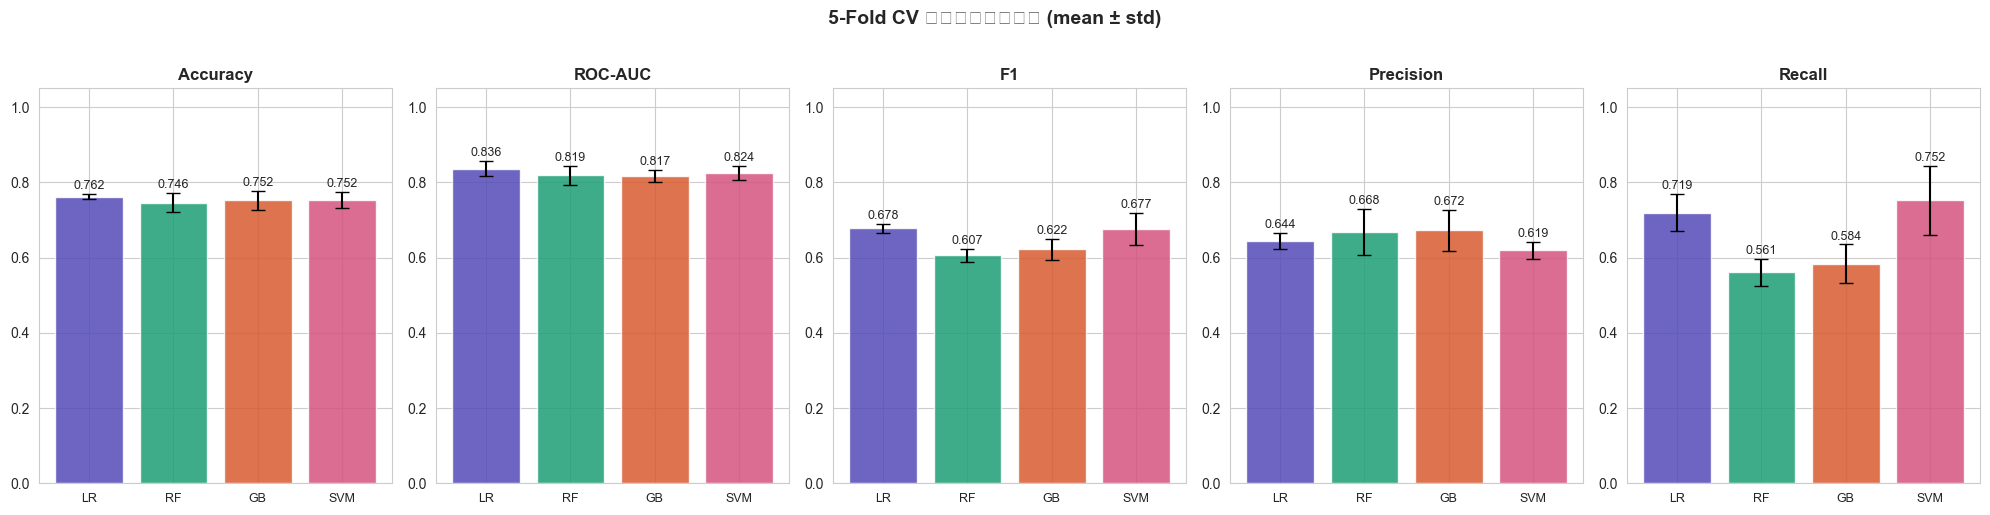

In [19]:
metrics_to_plot = ["accuracy", "roc_auc", "f1", "precision", "recall"]
metric_labels = ["Accuracy", "ROC-AUC", "F1", "Precision", "Recall"]
colors = ["#534AB7", "#1D9E75", "#D85A30", "#D4537E"]

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(20, 5), sharey=False)

for ax, metric, label in zip(axes, metrics_to_plot, metric_labels):
    model_names = list(cv_results.keys())
    means = [cv_results[m][f"test_{metric}"].mean() for m in model_names]
    stds = [cv_results[m][f"test_{metric}"].std() for m in model_names]

    bars = ax.bar(
        range(len(model_names)),
        means,
        color=colors,
        alpha=0.85,
        yerr=stds,
        capsize=5,
        error_kw={"linewidth": 1.5},
    )

    for bar, mean, std in zip(bars, means, stds):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + std + 0.005,
            f"{mean:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    ax.set_title(label, fontweight="bold")
    ax.set_xticks(range(len(model_names)))
    ax.set_xticklabels(["LR", "RF", "GB", "SVM"], fontsize=9)
    ax.set_ylim(0, 1.05)

plt.suptitle(
    "5-Fold CV შედეგები (mean ± std)", y=1.02, fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

### 4.3 Train vs Validation — Overfitting-ის შემოწმება

თუ train score მნიშვნელოვნად აღემატება validation score-ს, მოდელი overfitting-ს ახდენს:

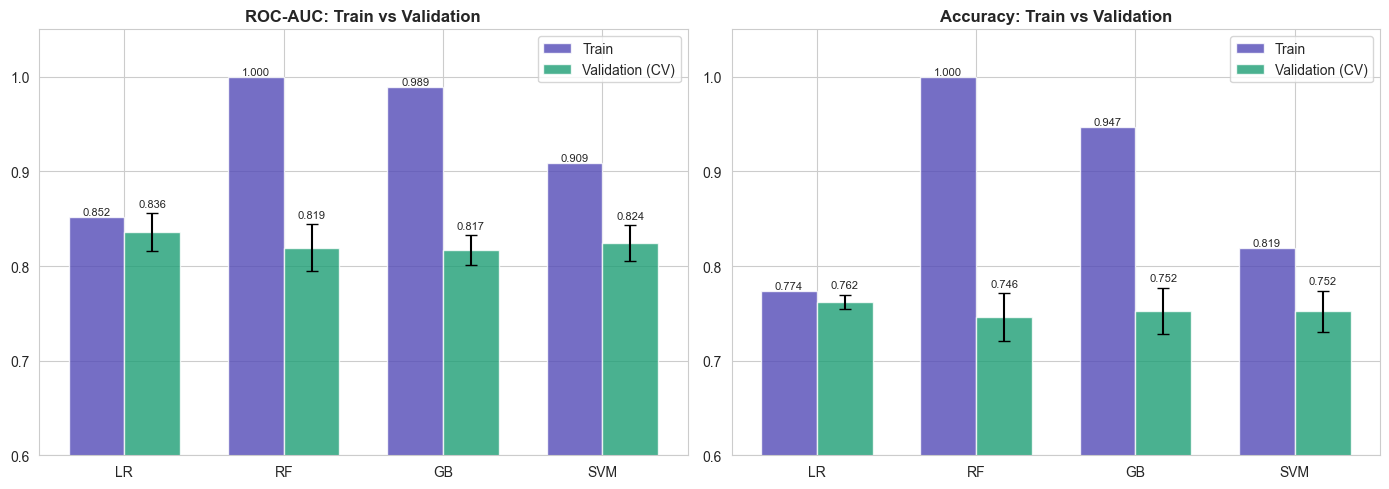

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, label in zip(axes, ["roc_auc", "accuracy"], ["ROC-AUC", "Accuracy"]):
    model_names = list(cv_results.keys())
    train_means = [cv_results[m][f"train_{metric}"].mean() for m in model_names]
    val_means = [cv_results[m][f"test_{metric}"].mean() for m in model_names]
    val_stds = [cv_results[m][f"test_{metric}"].std() for m in model_names]

    x = np.arange(len(model_names))
    width = 0.35

    bars_train = ax.bar(x - width / 2, train_means, width, label="Train", color="#534AB7", alpha=0.8)
    bars_val = ax.bar(
        x + width / 2,
        val_means,
        width,
        label="Validation (CV)",
        color="#1D9E75",
        alpha=0.8,
        yerr=val_stds,
        capsize=4,
    )

    ax.set_title(f"{label}: Train vs Validation", fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(["LR", "RF", "GB", "SVM"])
    ax.set_ylim(0.6, 1.05)
    ax.legend()
    ax.bar_label(bars_train, fmt="%.3f", fontsize=8)
    ax.bar_label(bars_val, fmt="%.3f", fontsize=8, padding=3)

plt.tight_layout()
plt.show()

### 4.4 Fold-by-Fold შედეგები — ROC-AUC

ვნახოთ, როგორ იქცევა თითოეული მოდელი ყოველ fold-ში ცალ-ცალკე:

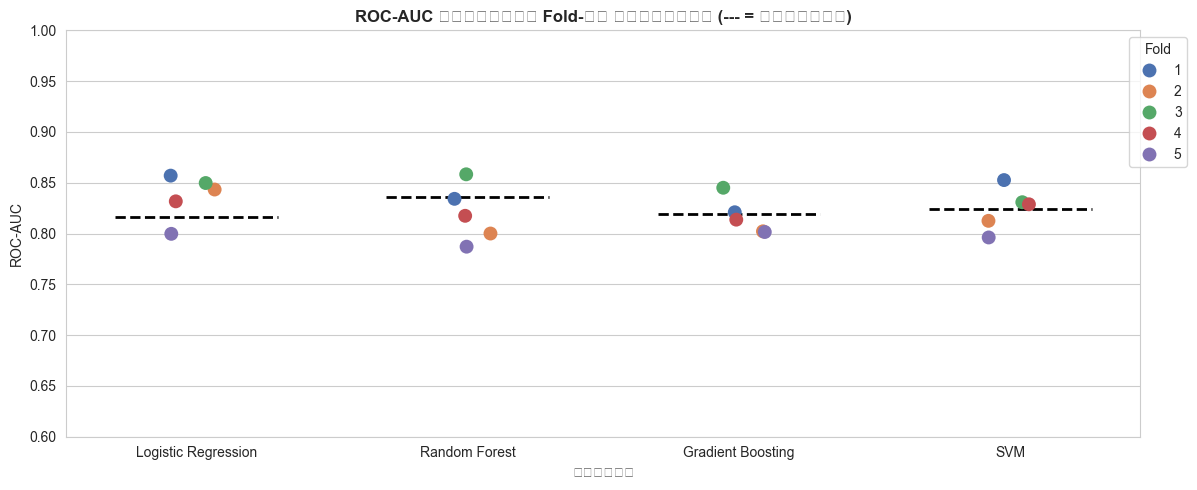

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))

fold_data = []
for name, res in cv_results.items():
    for fold_i, score in enumerate(res["test_roc_auc"]):
        fold_data.append({"მოდელი": name, "Fold": fold_i + 1, "ROC-AUC": score})

fold_df = pd.DataFrame(fold_data)

sns.stripplot(
    data=fold_df,
    x="მოდელი",
    y="ROC-AUC",
    hue="Fold",
    palette="deep",
    size=10,
    jitter=0.1,
    dodge=False,
    ax=ax,
)

model_means = fold_df.groupby("მოდელი")["ROC-AUC"].mean()
for i, (model, mean_val) in enumerate(model_means.items()):
    ax.hlines(mean_val, i - 0.3, i + 0.3, colors="black", linewidths=2, linestyles="--")

ax.set_title("ROC-AUC თითოეული Fold-ის მიხედვით (--- = საშუალო)", fontweight="bold")
ax.set_ylim(0.6, 1.0)
ax.legend(title="Fold", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

ესეიგი დაინპორტეთ ოთხი ალგორითმი , ლოჯისტიკური რეგრესია , შემთხვევითი ტყე , გრადიენტის მოკურცხვლა და სვმ , მთელი გულით არ ვიცი რატომ გრადიენტის კენ ვიყავი მაგრამ მიუხედავათ მაგისა ვერ ვიტყვით რომ რომელიმემ ცალსახად აჯობა , ოთხივეში შევცვალე ჰიპერპარამეტრი რამდენიმეჯერ ;დ , ქლაუდს კი არ უთქვამს როგორი დამეყენებინა , ჯერ ჰიპერ პარამეტრების გარეშე დიფაულტი რაც ქონდა ისე დავტოვე , მერე ჩემით ვეცადე რომ მომეპოვებინა ინფორმაცია და ისე შემეცვალა და საბოლოოდ ქლაუდს ვკითხე , შედეგები განსხვავდება ,სვმ თავიდან ძალიან იჩაგრებოდა , პარამეტრების დაყენებამ კი გზად დააყენა , გრადიენტის მოკურცხვლა არაპროგნოზირებადია მის მამობილს შემთხვევით ტყეს გავს , მაგრამ ეტყობა აჯობა მამამ , უფრო მკაცრია და თან რაღაცეების აღქმის უკეთესი უნარი აქვს , შემთხვევითი ტყის პარამეტრები მგონი უკეთ შევარჩი,და ქვრჩება ყველაზე სტაბილური , თვით ლოგისტიკური რეგრესია, აკურატულობაში აშკარად დაამტკიცა თავი , 1 ზე 1 თქვა 0 ზე 0 , ,ასევე ჩააბა როკის გამოცდა, გადაურჩა მკაცრ f1 ქულის შეფასებას ,სადაც ასევე ყველაზე კარგად ეჭირა თავი , პრესიზენშიც კარგად გამოაქვს თავი , რექალში კი რანდომ ფორეტი არის მოწინავე , მიუხედავათ მათი ასეთი თავდადებისა მე მაინც გრადიენტის მოკურცხვლისკენ ვარ :დ

## 5. მოდელების სწავლება Test Set-ზე შეფასება

CV-ის შედეგებზე დაყრდნობით ყველა მოდელს ვასწავლებთ სრულ train set-ზე და ვაფასებთ test set-ზე:

In [22]:
test_results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results[name] = {
        "model": model,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "auc": roc_auc_score(y_test, y_prob),
    }
    print(f"✓ {name} — დასრულდა")

✓ Logistic Regression — დასრულდა
✓ Random Forest — დასრულდა
✓ Gradient Boosting — დასრულდა
✓ SVM — დასრულდა


### 5.1 Classification Report

In [23]:
for name, res in test_results.items():
    print(f"{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(classification_report(y_test, res["y_pred"], target_names=["ჯანმრთელი", "დიაბეტი"]))
    print()

  Logistic Regression
              precision    recall  f1-score   support

   ჯანმრთელი       0.79      0.81      0.80       100
     დიაბეტი       0.63      0.61      0.62        54

    accuracy                           0.74       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.74      0.74      0.74       154


  Random Forest
              precision    recall  f1-score   support

   ჯანმრთელი       0.76      0.90      0.83       100
     დიაბეტი       0.72      0.48      0.58        54

    accuracy                           0.75       154
   macro avg       0.74      0.69      0.70       154
weighted avg       0.75      0.75      0.74       154


  Gradient Boosting
              precision    recall  f1-score   support

   ჯანმრთელი       0.76      0.90      0.83       100
     დიაბეტი       0.72      0.48      0.58        54

    accuracy                           0.75       154
   macro avg       0.74      0.69      0.70       154
weighted avg  

### 5.2 Confusion Matrices

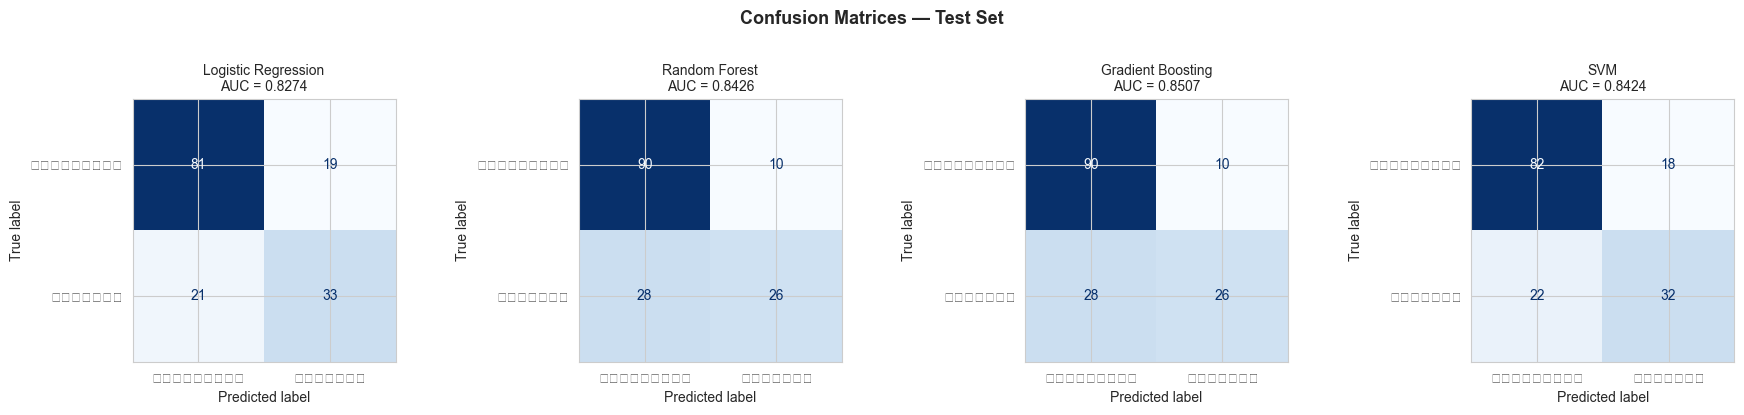

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, (name, res) in zip(axes, test_results.items()):
    cm = confusion_matrix(y_test, res["y_pred"])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["ჯანმრთელი", "დიაბეტი"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nAUC = {res['auc']:.4f}", fontsize=10)

plt.suptitle("Confusion Matrices — Test Set", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 5.3 ROC Curves

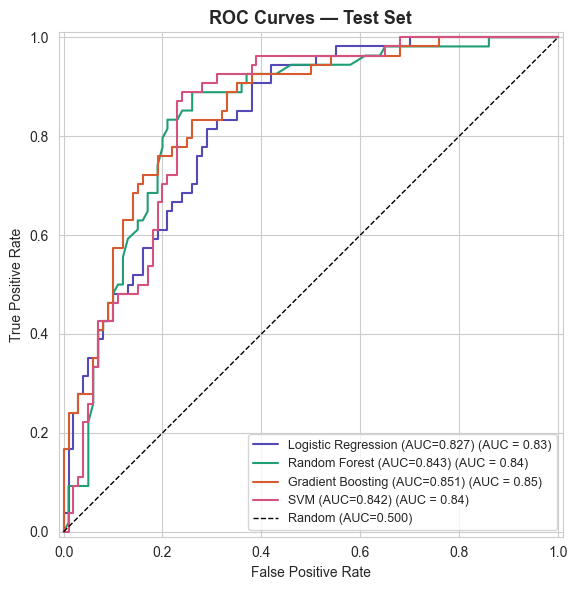

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))

roc_colors = ["#534AB7", "#1D9E75", "#D85A30", "#D4537E"]

for (name, res), color in zip(test_results.items(), roc_colors):
    RocCurveDisplay.from_predictions(
        y_test,
        res["y_prob"],
        name=f"{name} (AUC={res['auc']:.3f})",
        ax=ax,
        color=color,
    )

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random (AUC=0.500)")
ax.set_title("ROC Curves — Test Set", fontweight="bold", fontsize=13)
ax.legend(loc="lower right", fontsize=9)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")

plt.tight_layout()
plt.show()

## 6. Feature Importance

### 6.1 Random Forest Feature Importance

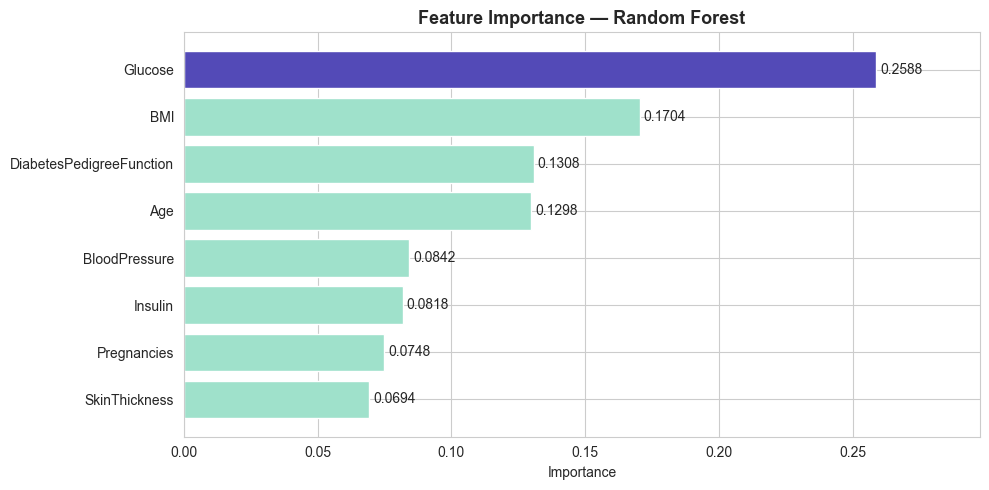

In [26]:
rf_model = test_results["Random Forest"]["model"]
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    importances.index,
    importances.values,
    color=["#534AB7" if v == importances.max() else "#9FE1CB" for v in importances.values],
)

ax.bar_label(bars, fmt="{:.4f}", padding=3)
ax.set_title("Feature Importance — Random Forest", fontweight="bold", fontsize=13)
ax.set_xlabel("Importance")
ax.set_xlim(0, importances.max() * 1.15)

plt.tight_layout()
plt.show()

### 6.2 Logistic Regression კოეფიციენტები

ლოგისტიკური რეგრესიის შემთხვევაში კოეფიციენტები გვეუბნება: პოზიტიური კოეფიციენტი ნიშნავს, რომ ნიშნის ზრდა დიაბეტის ალბათობას ზრდის, ხოლო ნეგატიური — ამცირებს:

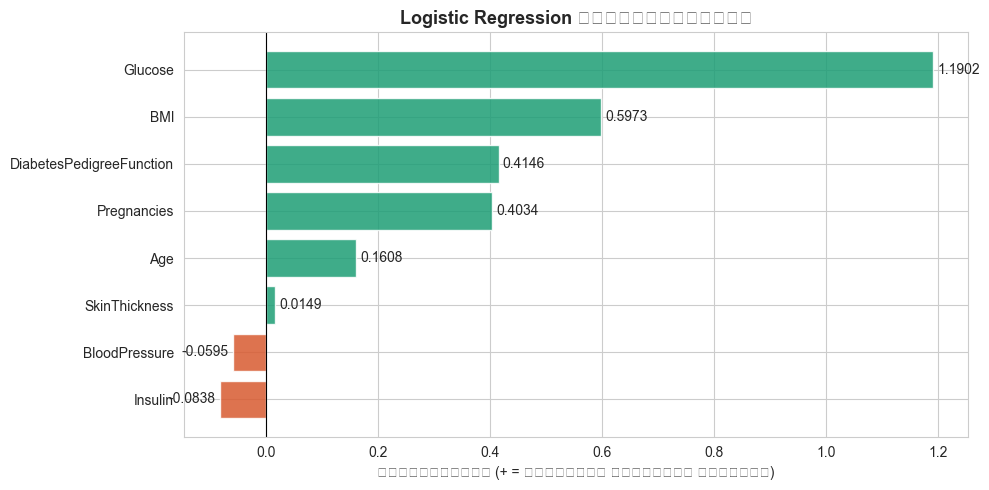

In [27]:
lr_model = test_results["Logistic Regression"]["model"]
coef_df = pd.Series(lr_model.coef_[0], index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))

colors_coef = ["#D85A30" if v < 0 else "#1D9E75" for v in coef_df.values]
bars = ax.barh(coef_df.index, coef_df.values, color=colors_coef, alpha=0.85)
ax.bar_label(bars, fmt="{:.4f}", padding=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression კოეფიციენტები", fontweight="bold", fontsize=13)
ax.set_xlabel("კოეფიციენტი (+ = დიაბეტის ალბათობა იზრდება)")

plt.tight_layout()
plt.show()

## 7. საბოლოო შეჯამება

In [28]:
final_df = pd.DataFrame(
    [
        {
            "მოდელი": name,
            "CV ROC-AUC (mean)": f"{cv_results[name]['test_roc_auc'].mean():.4f}",
            "CV ROC-AUC (±std)": f"±{cv_results[name]['test_roc_auc'].std():.4f}",
            "CV Accuracy (mean)": f"{cv_results[name]['test_accuracy'].mean():.4f}",
            "CV F1 (mean)": f"{cv_results[name]['test_f1'].mean():.4f}",
            "Test ROC-AUC": f"{test_results[name]['auc']:.4f}",
        }
        for name in models
    ]
).set_index("მოდელი")

final_df

,CV ROC-AUC (mean),CV ROC-AUC (±std),CV Accuracy (mean),CV F1 (mean),Test ROC-AUC
მოდელი,,,,,
Logistic Regression,0.8363,±0.0201,0.7622,0.6779,0.8274
Random Forest,0.8194,±0.0251,0.7460,0.6065,0.8426
Gradient Boosting,0.8167,±0.0160,0.7525,0.6216,0.8507
SVM,0.8242,±0.0190,0.7524,0.6770,0.8424


ესეიგი ცოტა ნახტომს გავაკეთებ და შემდეგ რამოდენიმე ეტაპს შევეცდები დასკვნაში დავწერო , ქლაუდმა და თქვენ როგორც ჩანს გადაწყვითეთ რომ მთლიან მონაცემების ნაცვლად სატესტო სეტი შქმნილი 154 მონაცმისგან შექმნილი ,ვაკვირდები დაბნეულობის მატრიცას და auc ი ამ შემთხვევაში გრადიენტ მოკურცხვლას აქვს კარგი შედეგი , 0=0 90 შემთხვევაში , 0 1 ეგონა 10 შემთხვევაში , 1 0 ეგონა28 შემთხვევაში და 1 1 26 შემთვევაში ეს ისედაც ჩანს დაწერით რატომ დავწერე არ ვიცი,როგორც ვახსენე სტაბილურობით და ცალსახიანობით არც ერთი არ გამოირჩევა სავარაუდოდ არსებობს სხვა უკეთესი ალგორითმი რომელიც უკეთესად მოერგება ამ მონაცემებს და უკეთს შედეგს გამოიტანს ,ამ ყველაფერს კი მიდასტურებს roc curves გრაფი , მოუხედავათ იმისა რომ გრადიენტს ტესტ სეტზე უკეთესი შედეგები აქვს , ვნახეთ რომ ვალიდაციის კუთხით ცოტა მოიკოჭლებს და ორჭოფობს , იმედია სწორად დავაკვირდი და სისულელები არ ვიბოდიალე , ბოდიშის მოხდით შევეცდები შემდეგში უკეთ დავაკვირდე , ახალი ალგორითმის ცდაც მინდოდა რომელიც ცოტა ხნის წინ ახსენით მგონი knn ის მსგავსი იყო მაგრამ რავი არ ვცადე მაინც და მაინც , კარგზე უკეთეს დღეს გისურვებთ როცა განიხილავთ მაშინ
პ.ს შესწორებისთვის და შეცდომების თვალსაღებად მზად ვარ .